# Lab 2 — Basics of Image Processing

Implements the Practice Assignment: 90° clockwise rotation, vertical mirroring, manual 8×8 thresholding, and repeated 2×2 top-left patch detection.

Each operation is presented in two styles. Style 1 uses OpenCV built-in operations. Style 2 uses OpenCV only to read images and Matplotlib to display them; the processing logic is written manually.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

LAB_DIR = Path.cwd()

def image_path(name):
    # Works when the notebook is opened from its Lab directory or repository root.
    candidates = [LAB_DIR / name, LAB_DIR / "Lab Practicals" / name]
    return next((path for path in candidates if path.exists()), candidates[0])

def show_images(images, titles, cmap=None, figsize=(14, 4)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    axes = np.atleast_1d(axes)
    for axis, image, title in zip(axes, images, titles):
        axis.imshow(image, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")
    plt.tight_layout()
    plt.show()


## Style 1 — OpenCV built-in operations

In [2]:
def rotate_and_mirror_cv(gray_image):
    clockwise = cv2.rotate(gray_image, cv2.ROTATE_90_CLOCKWISE)
    vertical_mirror = cv2.flip(gray_image, 1)
    return clockwise, vertical_mirror

def threshold_patch_cv(gray_image, threshold=50):
    patch = gray_image[:8, :8]
    return patch, (patch >= threshold).astype(np.uint8)

def repeated_top_left_patch_cv(binary_image):
    reference = binary_image[:2, :2]
    count = 0
    for row in range(binary_image.shape[0] - 1):
        for col in range(binary_image.shape[1] - 1):
            if np.array_equal(binary_image[row:row + 2, col:col + 2], reference):
                count += 1
    return count > 1, count


## Style 2 — DSA/manual implementation

In [3]:
def rotate_clockwise_manual(gray_image):
    height, width = gray_image.shape
    result = np.zeros((width, height), dtype=gray_image.dtype)
    for row in range(height):
        for col in range(width):
            result[col, height - 1 - row] = gray_image[row, col]
    return result

def mirror_vertical_manual(gray_image):
    height, width = gray_image.shape
    result = np.zeros_like(gray_image)
    for row in range(height):
        for col in range(width):
            result[row, width - 1 - col] = gray_image[row, col]
    return result

def threshold_patch_manual(gray_image, threshold=50):
    patch = gray_image[:8, :8]
    result = np.zeros((8, 8), dtype=np.uint8)
    for row in range(8):
        for col in range(8):
            result[row, col] = 1 if patch[row, col] >= threshold else 0
    return patch, result

def repeated_top_left_patch_manual(binary_image):
    reference = binary_image[:2, :2]
    count = 0
    for row in range(binary_image.shape[0] - 1):
        for col in range(binary_image.shape[1] - 1):
            matches = True
            for dr in range(2):
                for dc in range(2):
                    if binary_image[row + dr, col + dc] != reference[dr, dc]:
                        matches = False
            if matches:
                count += 1
    return count > 1, count


## Demonstration

Rotation equality: True
Mirror equality: True
Thresholded patch equality: True


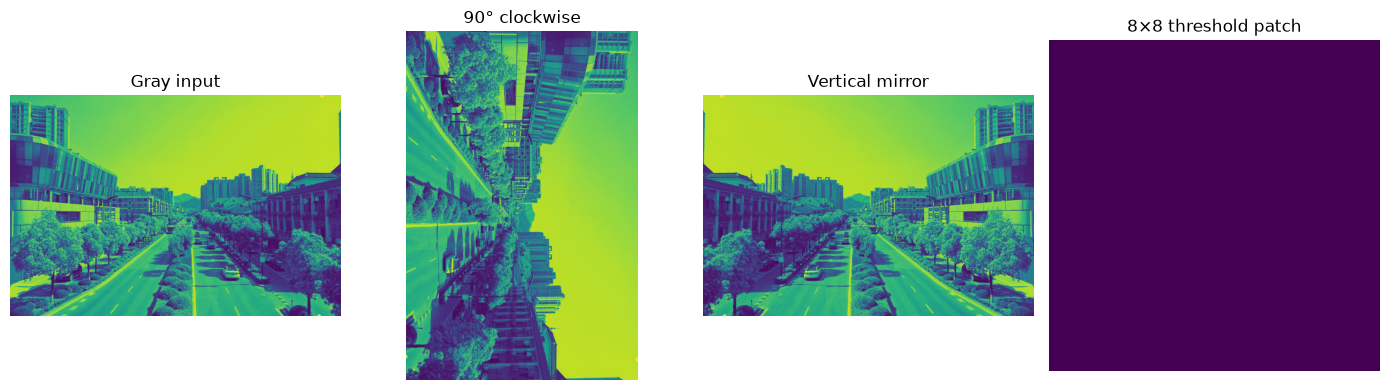

Repeated 2×2 patch: (True, 2)


In [4]:
source = image_path("Lab2/Images_Practice_Assignment/Natural_scene.jpg")
if not source.exists():
    source = image_path("Images_Practice_Assignment/Natural_scene.jpg")
colour = cv2.imread(str(source), cv2.IMREAD_COLOR)
if colour is None:
    colour = np.tile(np.arange(200, dtype=np.uint8), (200, 1))
gray = cv2.cvtColor(colour, cv2.COLOR_BGR2GRAY) if colour.ndim == 3 else colour
clockwise_cv, mirror_cv = rotate_and_mirror_cv(gray)
clockwise_manual = rotate_clockwise_manual(gray)
mirror_manual = mirror_vertical_manual(gray)
print("Rotation equality:", np.array_equal(clockwise_cv, clockwise_manual))
print("Mirror equality:", np.array_equal(mirror_cv, mirror_manual))
patch, binary_cv = threshold_patch_cv(gray)
_, binary_manual = threshold_patch_manual(gray)
print("Thresholded patch equality:", np.array_equal(binary_cv, binary_manual))
show_images([gray, clockwise_manual, mirror_manual, binary_manual],
            ["Gray input", "90° clockwise", "Vertical mirror", "8×8 threshold patch"])

sample = np.array([[0, 255, 255, 0], [255, 0, 0, 255],
                   [0, 0, 255, 0], [255, 255, 255, 0]], dtype=np.uint8)
print("Repeated 2×2 patch:", repeated_top_left_patch_manual(sample))
